# 10.2. Как рассчитать LTV по удержанию

Аналитика 101 · блок «Дата аналитика» · тема 10 «Юнит-экономика» · страница 10.2.

По данным учебного магазина сравним три прогноза удержания для 12 месячных когорт. Затем оценим LTV и рассчитаем бутстрэп-интервалы. В соседнем файле `ltv_cohorts.sql` тот же годовой LTV рассчитан в PostgreSQL по заказам клиентов.

Выполняйте ячейки сверху вниз. Для бутстрэпа понадобятся переменные из ячейки с моделями удержания.

Вывод получен на Python 3.13, pandas 3.0, SciPy 1.18 и matplotlib 3.10.

## Где лежат данные

Распакуйте архив главы так, чтобы папка `data/` находилась рядом с папкой урока. В `data/unit/` должны лежать `clients.csv`, `orders.csv`, `activity.csv` и `marketing_spend.csv`. Первая ячейка найдёт папку с материалами и сделает её рабочей. В ней появится график `tails.svg`.

In [1]:
import os
import pathlib
import platform

import matplotlib
import pandas as pd
import scipy

root = pathlib.Path.cwd()
while not (root / "data" / "unit").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/unit/
assert (root / "data" / "unit" / "orders.csv").exists(), \
    "Не найдена папка data/unit/. Скачайте общий набор темы 10 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| SciPy", scipy.__version__,
      "| matplotlib", matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | SciPy 1.18.1 | matplotlib 3.10.0


## Прогноз удержания

Сначала подберём параметры трёх моделей по месяцам 1–6 и сравним прогнозы с наблюдениями за месяцы 7–12. Затем заново оценим параметры по всем 12 месяцам и рассчитаем LTV на два и три года.

### Три модели удержания в SciPy

    факт  степенная  экспонента  плато
n                                     
7   15.4       15.8        12.6   15.6
8   14.3       14.9        10.6   15.0
9   13.5       14.2         9.0   14.6
10  13.2       13.6         7.6   14.4
11  12.7       13.1         6.5   14.3
12  11.8       12.6         5.5   14.2
средняя ошибка, п. п.: {'степенная': 0.54, 'экспонента': 4.86, 'плато': 1.18}
степенная по 1–12: a = 0.3612, b = 0.4361
LTV12 по данным: 1413 ₽; маржа на активного в хвосте: 475 ₽
            LTV24  LTV36
степенная    2011   2484
экспонента   1741   1826
плато        2109   2799


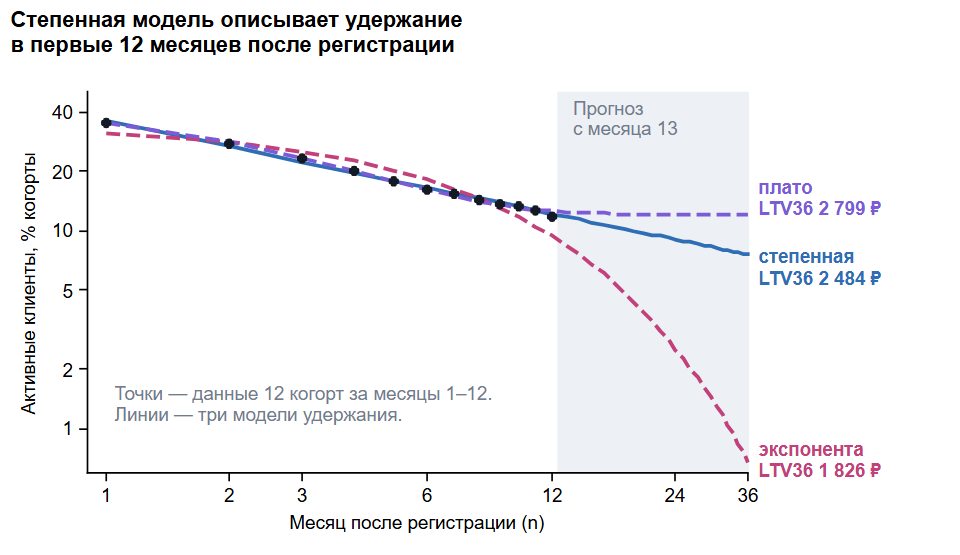

In [2]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

clients = pd.read_csv("data/unit/clients.csv", parse_dates=["signup_date"])
orders = pd.read_csv("data/unit/orders.csv", parse_dates=["order_date"])
activity = pd.read_csv("data/unit/activity.csv")

# маржинальный доход заказа по соглашению темы 10
orders["margin"] = np.where(orders.refunded == 1,
                            -2 * orders.delivery_cost - orders.payment_fee,
                            orders.revenue - orders.cogs - orders.delivery_cost - orders.payment_fee)
# месяц жизни n: 0 — месяц регистрации
clients["cohort"] = clients.signup_date.dt.strftime("%Y-%m")
c = clients.set_index("client_id")
start = c.signup_date.dt.year * 12 + c.signup_date.dt.month
activity["n"] = (activity.month.str[:4].astype(int) * 12 + activity.month.str[5:].astype(int)
                 - activity.client_id.map(start))
orders["n"] = orders.order_date.dt.year * 12 + orders.order_date.dt.month - orders.client_id.map(start)

# 12 когорт июля 2024 — июня 2025: месяцы жизни 0–12 есть у всех
grp = clients[clients.cohort.between("2024-07", "2025-06")]
size = grp.groupby("cohort").size()
pick = lambda t: t[t.client_id.isin(grp.client_id) & (t.n <= 12)].assign(cohort=lambda d: d.client_id.map(c.cohort))
act = pick(activity).pivot_table(index="cohort", columns="n", values="client_id", aggfunc="count")
marg = pick(orders).pivot_table(index="cohort", columns="n", values="margin", aggfunc="sum", fill_value=0)
r = act.sum() / size.sum()            # удержание группы: доля новичков, активных в месяц n
m = marg.sum() / act.sum()            # маржа на активного клиента в месяц n


def power(n, a, b):                   # степенная: отток со временем замедляется
    return a * n ** -b


def expo(n, a, k):                    # доля активных каждый месяц снижается на один и тот же процент
    return a * np.exp(-k * n)


def plateau(n, p, q, k):              # кривая выходит на уровень p
    return p + q * np.exp(-k * n)


models = {"степенная": (power, (0.4, 0.5)), "экспонента": (expo, (0.4, 0.1)), "плато": (plateau, (0.15, 0.3, 0.5))}

# 1) подгоняем по месяцам 1–6 и сверяем с месяцами 7–12
n6, n7 = np.arange(1, 7), np.arange(7, 13)
fit6 = {k: curve_fit(f, n6, r.loc[n6], p0=p0)[0] for k, (f, p0) in models.items()}
check = pd.DataFrame({"факт": r.loc[n7]} | {k: models[k][0](n7, *p) for k, p in fit6.items()}) * 100
print(check.round(1))
print("средняя ошибка, п. п.:", check.drop(columns="факт").sub(check["факт"], axis=0).abs().mean().round(2).to_dict())

# 2) оцениваем параметры по месяцам 1–12 и прогнозируем LTV за 24 и 36 месяцев
fit12 = {k: curve_fit(f, np.arange(1, 13), r.loc[1:], p0=p0)[0] for k, (f, p0) in models.items()}
print("степенная по 1–12: a = %.4f, b = %.4f" % tuple(fit12["степенная"]))
m_tail = marg[[10, 11, 12]].sum().sum() / act[[10, 11, 12]].sum().sum()   # доход на активного клиента за месяцы 10–12
known = (r * m).sum()                 # месяцы 0–12 — данные
ltv = {k: {H: known + (models[k][0](np.arange(13, H), *p) * m_tail).sum() for H in (24, 36)} for k, p in fit12.items()}
print(f"LTV12 по данным: {(r * m).loc[:11].sum():.0f} ₽; маржа на активного в хвосте: {m_tail:.0f} ₽")
print(pd.DataFrame(ltv).T.round(0).astype(int).rename(columns=lambda H: f"LTV{H}"))

# 3) рисунок: в логарифмических осях степенная кривая — прямая
import matplotlib.pyplot as plt
plt.rcParams.update({"svg.fonttype": "none", "font.size": 9})
fig, ax = plt.subplots(figsize=(6.4, 3.7))
nn = np.arange(1, 37)
ax.axvspan(12.5, 36, color="#edf0f4")
for k, col, dy in [("степенная", "#2f6db5", 0.85), ("экспонента", "#c2417a", 1), ("плато", "#7b5bd6", 1.2)]:
    y = models[k][0](nn, *fit12[k]) * 100
    ax.plot(nn, y, color=col, lw=1.8, ls="-" if k == "степенная" else "--")
    ax.text(38, y[-1] * dy, f"{k}\nLTV36 {ltv[k][36]:,.0f} ₽".replace(",", " "), color=col, va="center", fontweight="bold")
ax.plot(r.index[1:], r.loc[1:] * 100, "o", color="#141a24", ms=4)
ax.set(xscale="log", yscale="log", xlim=(0.9, 36), ylim=(0.6, 50),
       xlabel="Месяц после регистрации (n)", ylabel="Активные клиенты, % когорты")
ax.set_xticks([1, 2, 3, 6, 12, 24, 36], labels=["1", "2", "3", "6", "12", "24", "36"])
ax.set_yticks([1, 2, 5, 10, 20, 40], labels=["1", "2", "5", "10", "20", "40"])
ax.minorticks_off()
ax.spines[["top", "right"]].set_visible(False)
ax.text(13.5, 30, "Прогноз\nс месяца 13", color="#737c8f")
ax.text(1.05, 1.1, "Точки — данные 12 когорт за месяцы 1–12.\nЛинии — три модели удержания.", color="#737c8f")
fig.suptitle("Степенная модель описывает удержание\nв первые 12 месяцев после регистрации",
             x=0.01, ha="left", fontweight="bold", fontsize=10.5)
fig.tight_layout()
fig.subplots_adjust(right=0.78)
fig.savefig("tails.svg")

Функция curve_fit подбирает параметры методом наименьших квадратов. В p0 передают их начальные значения. Для проверки модели обучают на месяцах 1–6, а для итогового прогноза используют месяцы 1–12. Поэтому таблица прогнозов совпадает с результатами анимации.

## Интервалы для LTV

В каждой из 2 000 повторных выборок случайно выберем 12 когорт с возвращением. Для каждой выборки заново рассчитаем LTV. Начальное значение генератора задано заранее, так что при повторном запуске получатся те же интервалы.

### Как оценить неопределённость LTV по когортам

In [3]:
# Перед запуском выполните предыдущую ячейку. В ней определены size, act, marg, power, pick, grp и orders.
S, A, M = size.to_numpy(), act.to_numpy(), marg.to_numpy()   # 12 когорт × месяцы 0–12


def ltv12_24(i):
    """LTV12 по данным и LTV24 со степенным хвостом для набора когорт i."""
    s = S[i].sum()
    (a, b), _ = curve_fit(power, np.arange(1, 13), A[i, 1:].sum(0) / s, p0=(0.4, 0.5))
    m_tail = M[i, 10:].sum() / A[i, 10:].sum()
    return M[i, :12].sum() / s, M[i].sum() / s + (power(np.arange(13, 24), a, b) * m_tail).sum()


rng = np.random.default_rng(10)
boot = np.array([ltv12_24(rng.integers(0, 12, size=12)) for _ in range(2000)])   # 12 когорт с возвращением
point = ltv12_24(np.arange(12))
for j, name in enumerate(["LTV12", "LTV24, степенной хвост"]):
    lo, hi = np.percentile(boot[:, j], [2.5, 97.5])
    print(f"{name}: {point[j]:.0f} ₽, 95% интервал {lo:.0f}–{hi:.0f} ₽")

# Для каждого канала повторяем бутстрэп по когортам. CAC считаем по расходам и регистрациям за те же 12 месяцев.
spend = pd.read_csv("data/unit/marketing_spend.csv").query("'2024-07' <= month <= '2025-06'").groupby("channel").spend.sum()
o12 = pick(orders).query("n < 12").merge(clients[["client_id", "channel"]], on="client_id")
mar_ch = o12.pivot_table(index="cohort", columns="channel", values="margin", aggfunc="sum")
cnt_ch = grp.pivot_table(index="cohort", columns="channel", values="client_id", aggfunc="count")
idx = rng.integers(0, 12, size=(2000, 12))
rows = {}
for ch in cnt_ch.columns:
    b = mar_ch[ch].to_numpy()[idx].sum(1) / cnt_ch[ch].to_numpy()[idx].sum(1)
    rows[ch] = [cnt_ch[ch].sum(), mar_ch[ch].sum() / cnt_ch[ch].sum(), *np.percentile(b, [2.5, 97.5]),
                spend.get(ch, np.nan) / cnt_ch[ch].sum()]
print(pd.DataFrame(rows, index=["клиентов", "LTV12", "от", "до", "CAC"]).T.round(0).astype("Int64"))

LTV12: 1413 ₽, 95% интервал 1353–1473 ₽
LTV24, степенной хвост: 2011 ₽, 95% интервал 1900–2111 ₽


          клиентов  LTV12    от    до   CAC
органика     11707   1636  1538  1725  <NA>
партнёры      3727   1484  1371  1604  1254
поиск         6668   1540  1433  1660  1454
соцсети       3888    455   420   495  2816


Перед запуском выполните предыдущую ячейку. В строке органического канала <NA> означает, что в выгрузке нет рекламных расходов по этому каналу и CAC не рассчитан. У генератора случайных чисел задано начальное значение, поэтому при повторном запуске границы интервалов совпадут.